# 05 - VGGT-Long, step by step

A picture book of one SLAM system on one robot. We follow a wheeled robot with a single RGB camera through
three recordings, let a 3D foundation model reconstruct where it drove and what the room looks like,
and check every step against ground truth.

**System.** VGGT-Long (Deng et al., ICRA 2026) wraps the foundation model VGGT (Wang et al., CVPR 2025) into a
SLAM pipeline for long image sequences. **Data.** M3DGR (Zhang et al., IROS 2025), three indoor sequences with
motion-capture ground truth.

The notebook only **reads** results produced by the pipeline (`results/`, `data/M3DGR/`), so it runs in a few
minutes without a GPU. How the runs were made is shown in Section 3.

| Section | Question |
|---|---|
| 1 | What does the robot see? |
| 2 | How does VGGT-Long turn images into a trajectory? |
| 3 | How was it run (cluster and laptop)? |
| 4 | How close is the trajectory to the truth? |
| 5 | Why does it fail when the light goes out? |
| 6 | How good is the map? |
| 6b | Does a LiDAR do better? (FAST-LIO2 as backup) |
| 7 | What does a 16 GB laptop GPU cost in accuracy? |
| 8 | Live demo in Lichtblick / Foxglove |
| 9 | Take-aways |

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from evo.core import sync
from evo.tools import file_interface
from scipy.spatial import cKDTree

from pipeline.common import load_sequences, load_system_config
from pipeline.visualize import align_full, _read_ply_xyzrgb
from pipeline.map_eval import icp, voxel_thin

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.precision", 3)

CFG = load_sequences()
DATA = ROOT / CFG["data_root"]
RES = ROOT / "results"
SEQS = [s["name"] for s in CFG["sequences"]]
GT = {s: file_interface.read_tum_trajectory_file(str(DATA / s / "gt_tum.txt")) for s in SEQS}
C_GT, C_EST, C_LAP = "0.55", "#0072B2", "#D55E00"


def load_est(slug, seq, run="run_00"):
    return file_interface.read_tum_trajectory_file(str(RES / slug / seq / run / "trajectory_tum.txt"))


def aligned(slug, seq, run="run_00"):
    # Sim(3) alignment, identical to pipeline.evaluate; returns the aligned trajectory and (s, R, t)
    return align_full(GT[seq], load_est(slug, seq, run), True, CFG["evaluation"]["t_max_diff"])


def frame_list(seq):
    rows = [l.split() for l in (DATA / seq / "rgb.txt").read_text().splitlines() if not l.startswith("#")]
    return np.array([float(r[0]) for r in rows]), [r[1] for r in rows]

## 1. What does the robot see?

The robot is a small differential-drive platform. Its RealSense D435i colour camera looks forward at 30 Hz,
640 x 480, mounted about 0.8 m above the floor. All three sequences were recorded in the same motion-capture
hall (~6.5 m x 3 m driving area), so the ground truth (OptiTrack, ~300 Hz) is accurate to millimetres.

| Sequence | What makes it hard |
|---|---|
| `Dynamic01` | nominal case: good light, slow, people walking through the image |
| `Sha-turn01` | twice as fast, sharp turns, wheel slip |
| `Varying-illu01` | the light is switched off and on repeatedly |

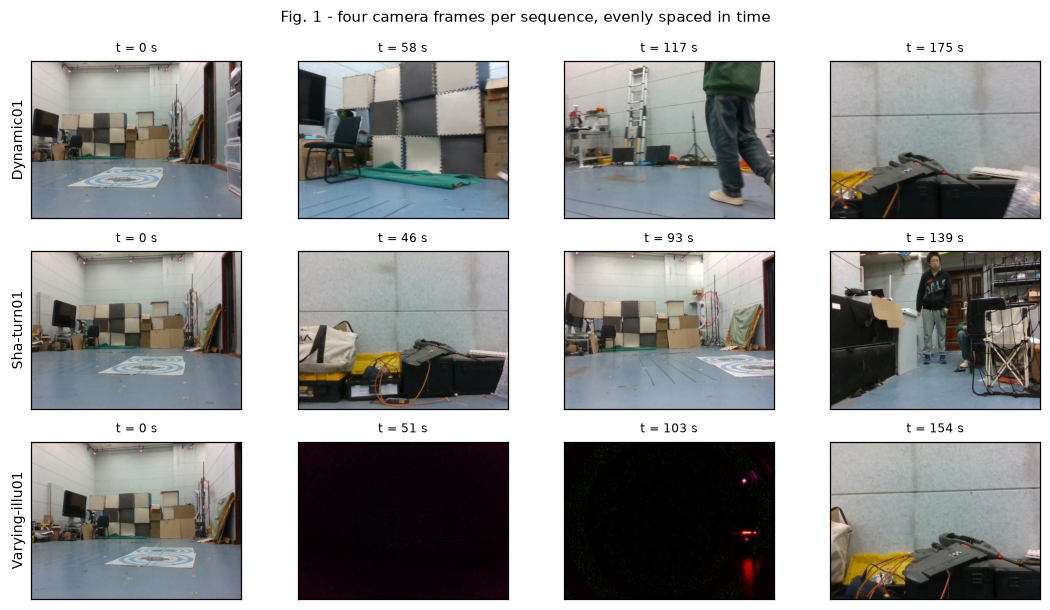

In [2]:
fig, axes = plt.subplots(3, 4, figsize=(10, 5.6))
for row, s in zip(axes, SEQS):
    t, files = frame_list(s)
    for ax, i in zip(row, np.linspace(0, len(files) - 1, 4).astype(int)):
        img = cv2.cvtColor(cv2.imread(str(DATA / s / files[i])), cv2.COLOR_BGR2RGB)
        ax.imshow(img); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_title(f"t = {t[i] - t[0]:.0f} s", fontsize=8)
    row[0].set_ylabel(s, fontsize=9)
fig.suptitle("Fig. 1 - four camera frames per sequence, evenly spaced in time", fontsize=10)
plt.tight_layout()

,duration_s,path_length_m,frames_at_10Hz
sequence,,,
Dynamic01,175.15,72.219,1751
Sha-turn01,138.95,98.315,1389
Varying-illu01,154.08,73.695,1540


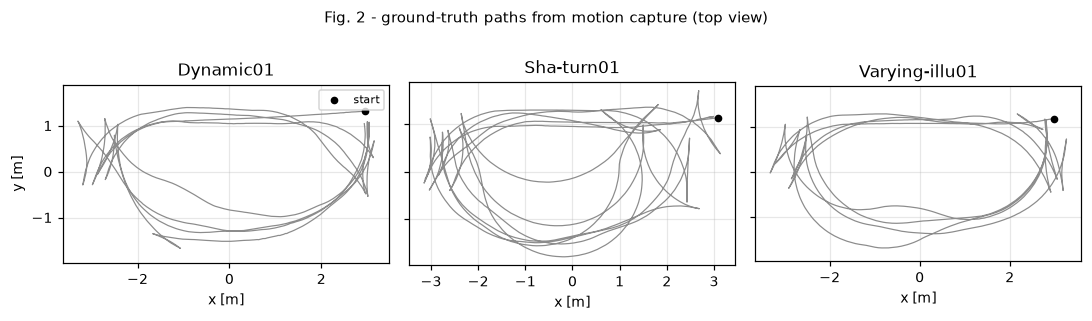

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
rows = []
for ax, s in zip(axes, SEQS):
    p = GT[s].positions_xyz
    ax.plot(p[:, 0], p[:, 1], c=C_GT, lw=0.8)
    ax.plot(*p[0, :2], "o", c="k", ms=4, label="start")
    ax.set_aspect("equal"); ax.set_title(s); ax.set_xlabel("x [m]")
    rows.append({"sequence": s, "duration_s": GT[s].timestamps[-1] - GT[s].timestamps[0],
                 "path_length_m": GT[s].path_length, "frames_at_10Hz": len(list((DATA / s / "rgb_step3").glob("*.jpg")))})
axes[0].set_ylabel("y [m]"); axes[0].legend(fontsize=7)
fig.suptitle("Fig. 2 - ground-truth paths from motion capture (top view)", fontsize=10)
plt.tight_layout()
pd.DataFrame(rows).set_index("sequence")

**Reading Fig. 2:** the robot drives laps around the hall, 70-100 m per sequence in 2-3 minutes. Laps are good
for SLAM: the robot comes back to places it has seen, so loop closure can correct drift.

## 2. How does VGGT-Long turn images into a trajectory?

**VGGT** is a feed-forward transformer: it takes a set of images and directly predicts, in one pass, the camera
pose and a depth map for every image. No feature matching, no bundle adjustment. Its catch: memory grows with
the number of images, so a whole sequence (1400-1750 frames) does not fit on any GPU.

**VGGT-Long** makes it work on long sequences in three steps ("chunk it, loop it, align it"):

1. **Chunk it** - cut the image stream into overlapping chunks (default 60 frames, 30 shared with the next chunk)
   and run VGGT on each chunk separately.
2. **Align it** - each chunk has its own coordinate frame *and its own scale* (a single camera cannot measure
   metric size). Neighbouring chunks are aligned on their shared frames with a **Sim(3)** transform
   (rotation, translation, scale).
3. **Loop it** - image retrieval (DINOv2 + SALAD) finds places seen before; a pose-graph optimisation over the
   chunk transforms removes accumulated drift.

The input is subsampled to **10 Hz** (every 3rd frame), as recommended upstream: very dense frames with tiny
motion increase drift.

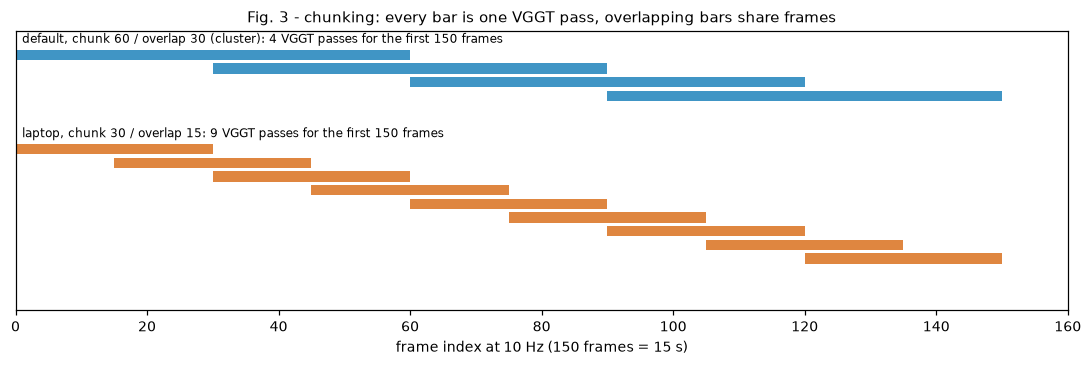

In [4]:
def draw_chunks(ax, chunk, overlap, y0, color, label, n_frames=150):
    # one row per chunk (staircase), so the shared frames between neighbours are visible
    starts = list(range(0, n_frames - overlap, chunk - overlap))
    for k, start in enumerate(starts):
        ax.add_patch(Rectangle((start, y0 - 0.12 * k), chunk, 0.09, color=color, alpha=0.75, lw=0))
    ax.text(1, y0 + 0.15, f"{label}: {len(starts)} VGGT passes for the first {n_frames} frames", fontsize=8)
    return y0 - 0.12 * len(starts)

fig, ax = plt.subplots(figsize=(10, 3.4))
y = draw_chunks(ax, 60, 30, 1.95, C_EST, "default, chunk 60 / overlap 30 (cluster)")
draw_chunks(ax, 30, 15, y - 0.35, C_LAP, "laptop, chunk 30 / overlap 15")
ax.set_xlim(0, 160); ax.set_ylim(-0.25, 2.2); ax.set_yticks([]); ax.grid(False)
ax.set_xlabel("frame index at 10 Hz (150 frames = 15 s)")
ax.set_title("Fig. 3 - chunking: every bar is one VGGT pass, overlapping bars share frames", fontsize=10)
plt.tight_layout()

**Reading Fig. 3:** with half the chunk size there are twice as many chunks and twice as many Sim(3) links.
Every link can add a small error, so smaller chunks should drift more. Section 7 measures how much.

## 3. How was it run?

Every run goes through the same pipeline (`python -m pipeline.run_all --system <slug>`), which starts the
pinned container (`docker/vggt_long`), converts the output to TUM format and logs CPU, RAM and GPU memory.
Parameters come from `config/systems/<slug>.yaml`; every deviation from the authors' defaults is written there.

In [5]:
for slug in ["vggt_long", "vggt_long_16gb"]:
    cfg = load_system_config(slug)
    print(f"--- {slug}: {cfg['system']}")
    print("parameters:", cfg["parameters"])
    for d in cfg["deviations_from_defaults"]:
        print(" deviation:", " ".join(d.split()))
    meta = RES / slug / "Dynamic01" / "run_00" / "meta.json"
    if meta.exists():
        import json
        m = json.loads(meta.read_text())
        print(" hardware:", m["hardware"]["gpu"])
    print()

--- vggt_long: VGGT-Long
parameters: {'frame_step': 3}
 deviation: Input frame rate 10 Hz instead of the recorded 30 Hz (frame_step 3). Upstream README, 'Possible problems' d: very dense input with small motion between frames increases drift, extract frames at a lower rate. The authors' own benchmarks (KITTI) are 10 Hz. Evaluation matches poses by timestamp, so ATE stays comparable.
 hardware: NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB

--- vggt_long_16gb: VGGT-Long 16 GB (chunk 30)
parameters: {'frame_step': 3, 'chunk_size': 30, 'overlap': 15, 'loop_chunk_size': 15, 'low_disk': True}
 deviation: chunk_size 30 / overlap 15 instead of 60 / 30, to fit 16 GB of GPU memory (upstream was developed on a 24 GB RTX 4090; nvidia-smi showed 28-45 GB on the cluster, depending on how much the allocator caches). Overlap kept at half the chunk, as in the default.
 deviation: loop_chunk_size 15 instead of 20: a loop chunk holds 2 x loop_chunk_size images, so 40 images ran out of memory a

Two configurations:

- **`vggt_long`** - the authors' defaults, 5 runs per sequence on the AIT ADA cluster (RTX PRO 6000 Blackwell,
  48-96 GB). This is the main result.
- **`vggt_long_16gb`** - the same system on an RTX 3080 Ti laptop GPU (16 GB). With the default chunk, `nvidia-smi` showed
  28-45 GB on the cluster, so the chunk is halved to 30 frames. The weights stay in fp32 as upstream; they are only loaded via the CPU
  instead of directly onto the GPU, which avoids holding them twice during loading.

## 4. How close is the trajectory to the truth?

**Metric: ATE** (absolute trajectory error, Sturm et al. 2012): after aligning the estimated trajectory to the
ground truth, the RMSE of the position differences, computed with `evo`. A monocular system cannot know the true
scale, so the alignment is **Sim(3)** (Umeyama 1991; Zhang & Scaramuzza 2018). The scale factor it needs is
reported as well. Robustness follows ORB-SLAM3: success rate k/N and tracked fraction.

In [6]:
metrics = pd.read_csv(RES / "metrics.csv")
iqr = lambda x: x.quantile(0.75) - x.quantile(0.25)
tab = (metrics[metrics.slug == "vggt_long"].groupby("sequence")
       .agg(success=("success", "sum"), runs=("run", "count"), ate_rmse_m=("ate_rmse_m", "median"),
            ate_iqr_m=("ate_rmse_m", iqr), ate_max_m=("ate_max_m", "median"), scale=("scale", "median"),
            tracked=("tracked_fraction", "median")).loc[SEQS])
tab["ate_per_path_%"] = 100 * tab.ate_rmse_m / [GT[s].path_length for s in SEQS]
tab

,success,runs,ate_rmse_m,ate_iqr_m,ate_max_m,scale,tracked,ate_per_path_%
sequence,,,,,,,,
Dynamic01,5,5,0.146,1.120e-05,0.290,5.241,0.999,0.202
Sha-turn01,5,5,0.264,4.601e-06,0.647,5.811,0.999,0.268
Varying-illu01,5,5,2.346,4.533e-07,3.425,2.076,0.999,3.184


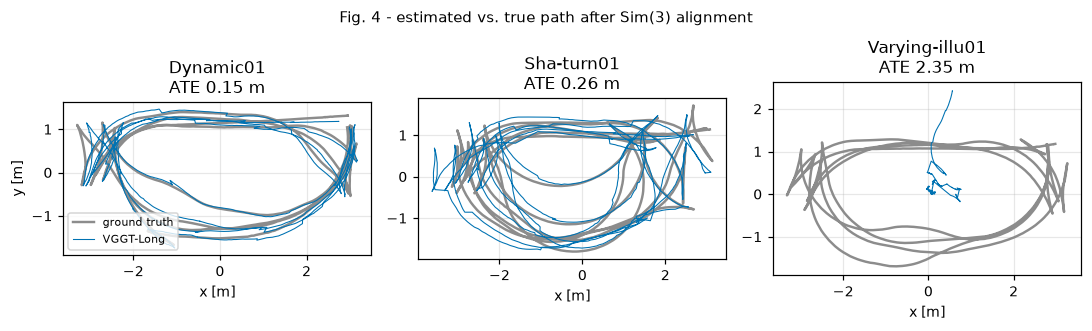

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(10, 2.9))
for ax, s in zip(axes, SEQS):
    e, _ = aligned("vggt_long", s)
    ax.plot(GT[s].positions_xyz[:, 0], GT[s].positions_xyz[:, 1], c=C_GT, lw=1.6, label="ground truth")
    ax.plot(e.positions_xyz[:, 0], e.positions_xyz[:, 1], c=C_EST, lw=0.7, label="VGGT-Long")
    ax.set_aspect("equal"); ax.set_title(f"{s}\nATE {tab.loc[s, 'ate_rmse_m']:.2f} m"); ax.set_xlabel("x [m]")
axes[0].set_ylabel("y [m]"); axes[0].legend(fontsize=7, loc="lower left")
fig.suptitle("Fig. 4 - estimated vs. true path after Sim(3) alignment", fontsize=10)
plt.tight_layout()

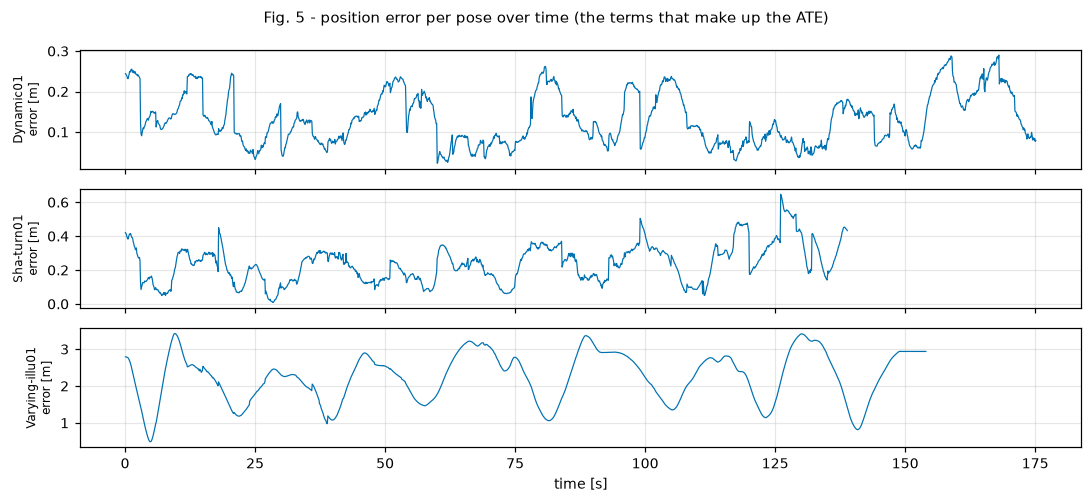

In [8]:
def error_over_time(slug, seq, run="run_00"):
    e, _ = aligned(slug, seq, run)
    r, a = sync.associate_trajectories(GT[seq], e, max_diff=CFG["evaluation"]["t_max_diff"])
    return r.timestamps - GT[seq].timestamps[0], np.linalg.norm(r.positions_xyz - a.positions_xyz, axis=1)

fig, axes = plt.subplots(3, 1, figsize=(10, 4.6), sharex=True)
for ax, s in zip(axes, SEQS):
    t, err = error_over_time("vggt_long", s)
    ax.plot(t, err, c=C_EST, lw=0.8)
    ax.set_ylabel(f"{s}\nerror [m]", fontsize=8)
axes[-1].set_xlabel("time [s]")
fig.suptitle("Fig. 5 - position error per pose over time (the terms that make up the ATE)", fontsize=10)
plt.tight_layout()

**Is that good?** The M3DGR authors ran over 40 systems on exactly these sequences (Zhang et al. 2025, Table VII,
ATE RMSE in m, "x" = failed). The camera-only rows are the fair comparison. Their alignment protocol may differ
slightly from ours, so read this as context, not as a ranking.

In [9]:
lit = pd.DataFrame({  # Zhang et al., IROS 2025 (M3DGR), Table VII
    "ORB-SLAM2 (mono RGB)":      {"Dynamic01": 0.14, "Sha-turn01": 1.54, "Varying-illu01": np.nan},
    "TartanVO (mono RGB)":       {"Dynamic01": 2.37, "Sha-turn01": 2.09, "Varying-illu01": 2.17},
    "VINS-Mono (RGB + IMU)":     {"Dynamic01": 0.43, "Sha-turn01": 0.36, "Varying-illu01": 2.70},
    "FAST-LIO2 (LiDAR + IMU)":   {"Dynamic01": 0.13, "Sha-turn01": 0.18, "Varying-illu01": 0.11},
}).loc[SEQS]
lit.insert(0, "VGGT-Long (ours, mono RGB)", tab.ate_rmse_m)
lit.round(2).fillna("x")

C:\Users\BitschE\AppData\Local\Temp\ipykernel_39264\1475446258.py:8: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  lit.round(2).fillna("x")


,"VGGT-Long (ours, mono RGB)",ORB-SLAM2 (mono RGB),TartanVO (mono RGB),VINS-Mono (RGB + IMU),FAST-LIO2 (LiDAR + IMU)
Dynamic01,0.15,0.14,2.37,0.43,0.13
Sha-turn01,0.26,1.54,2.09,0.36,0.18
Varying-illu01,2.35,x,2.17,2.70,0.11


**Reading Table / Fig. 4-5:** on the two well-lit sequences VGGT-Long follows the truth to 0.15 m and 0.26 m ATE,
about 0.2-0.3 % of the distance driven, from one uncalibrated camera. The 5 runs differ by less than a
millimetre (IQR column): inference is deterministic, so failures are systematic, not bad luck.
Next to the published baselines, VGGT-Long matches ORB-SLAM2 on `Dynamic01` and is clearly better on the sharp
turns of `Sha-turn01`, where ORB-SLAM2 drifts to 1.5 m, without being tuned for this camera.
`Varying-illu01` is different: 2.3 m ATE, yet the tracked fraction is still 99.9 %. Section 5 explains why.

## 5. Why does it fail when the light goes out?

A classical visual SLAM system reports *tracking lost* on a black image. VGGT-Long does not: VGGT always
predicts a pose and a depth map. Chunks made of black frames contain no geometry, so their Sim(3) link to the
neighbours gets a wrong scale, and that error is carried into everything that follows.

share of dark frames 45%; mean error: dark 2.08 m, lit 2.39 m
light comes back 5 times; brightness peaks right after: [208 240 221 232 203], median when lit: 133


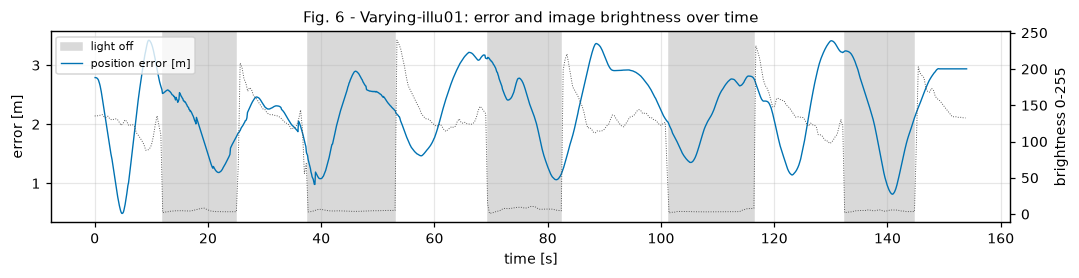

In [10]:
s = "Varying-illu01"
t_img, files = frame_list(s)
idx = np.arange(0, len(files), 10)
bright = np.array([cv2.imread(str(DATA / s / files[i]), cv2.IMREAD_GRAYSCALE).mean() for i in idx])
t_b = t_img[idx] - t_img[0]
t, err = error_over_time("vggt_long", s)

fig, ax = plt.subplots(figsize=(10, 2.6))
ax.fill_between(t_b, 0, 1, where=bright < 20, color="0.85", transform=ax.get_xaxis_transform(), label="light off")
ax.plot(t, err, c=C_EST, lw=0.9, label="position error [m]")
ax2 = ax.twinx(); ax2.plot(t_b, bright, c="0.3", lw=0.6, ls=":", label="brightness"); ax2.set_ylabel("brightness 0-255")
ax2.grid(False)
ax.set_xlabel("time [s]"); ax.set_ylabel("error [m]"); ax.legend(loc="upper left", fontsize=7)
ax.set_title("Fig. 6 - Varying-illu01: error and image brightness over time", fontsize=10)
plt.tight_layout()
dark = np.interp(t, t_b, bright) < 20
print(f"share of dark frames {dark.mean():.0%}; mean error: dark {err[dark].mean():.2f} m, lit {err[~dark].mean():.2f} m")
is_dark = bright < 20
returns = np.where(is_dark[:-1] & ~is_dark[1:])[0] + 1
peaks = [bright[k:k + 10].max() for k in returns]              # first ~3 s after the light comes back
print(f"light comes back {len(returns)} times; brightness peaks right after: {np.round(peaks).astype(int)}, "
      f"median when lit: {np.median(bright[~is_dark]):.0f}")

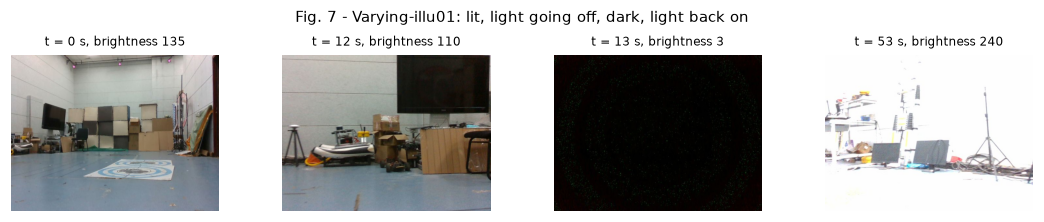

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(10, 2.0))
first_dark = np.argmax(bright < 20)
k = returns[np.argmax(peaks)]
back_on = k + np.argmax(bright[k:k + 10])                      # the most washed-out frame after a return
picks = [0, first_dark - 1, first_dark + 3, back_on]
for ax, k in zip(axes, picks):
    i = idx[k]
    ax.imshow(cv2.cvtColor(cv2.imread(str(DATA / s / files[i])), cv2.COLOR_BGR2RGB))
    ax.set_title(f"t = {t_b[k]:.0f} s, brightness {bright[k]:.0f}", fontsize=8); ax.axis("off")
fig.suptitle("Fig. 7 - Varying-illu01: lit, light going off, dark, light back on", fontsize=10)
plt.tight_layout()

**Reading Fig. 6-7:** the error is not confined to the dark phases; it is just as large when the light is on.
The dark chunks broke the scale between chunks, so the whole reconstruction shrank (scale factor ~2.1 instead
of ~5.5, see the table in Section 4). Fig. 7 and the printed peaks add a second camera problem: every time the
light comes back, the auto-exposure overshoots and the first second of frames is washed out. This is a **silent failure**: the tracked fraction says everything is fine,
only ATE, the scale factor and the map metrics reveal it. A deployment would need an explicit image-quality gate.

## 6. How good is the map?

M3DGR has no reference map, so we built one: the MID-360 LiDAR scans placed along the motion-capture poses
(`pipeline/reference_map.py`, people filtered out). The VGGT-Long point cloud is aligned via the trajectory and
refined with ICP (Tanks and Temples protocol, Knapitsch et al. 2017).

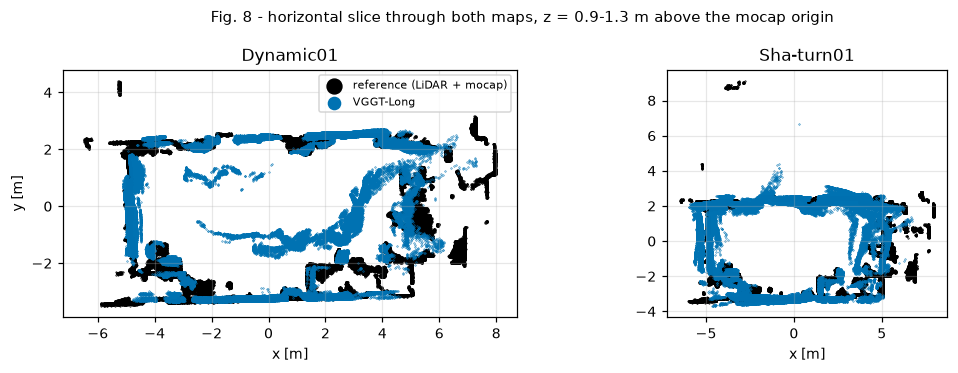

In [12]:
def map_pair(slug, seq, run="run_00", every=3):
    # VGGT-Long map in the mocap frame (trajectory alignment + ICP refinement, as in pipeline.map_eval)
    _, (sc, R, t) = aligned(slug, seq, run)
    ref = voxel_thin(_read_ply_xyzrgb(DATA / seq / "reference_map.ply")[0])
    est = sc * _read_ply_xyzrgb(RES / slug / seq / run / "map.ply")[0][::every] @ R.T + t
    est_icp, (s_i, r_i, _) = icp(est, cKDTree(ref), ref, with_scale=True)
    return voxel_thin(est_icp), ref

maps = {s: map_pair("vggt_long", s) for s in ["Dynamic01", "Sha-turn01"]}
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, (s, (est, ref)) in zip(axes, maps.items()):
    for pts, c, lab, size in ((ref, "k", "reference (LiDAR + mocap)", 0.15), (est, C_EST, "VGGT-Long", 0.1)):
        sl = (pts[:, 2] > 0.9) & (pts[:, 2] < 1.3)
        ax.scatter(pts[sl, 0], pts[sl, 1], s=size, c=c, label=lab, rasterized=True)
    ax.set_aspect("equal"); ax.set_title(s); ax.set_xlabel("x [m]")
axes[0].set_ylabel("y [m]"); axes[0].legend(markerscale=25, fontsize=7, loc="upper right")
fig.suptitle("Fig. 8 - horizontal slice through both maps, z = 0.9-1.3 m above the mocap origin", fontsize=10)
plt.tight_layout()

**Map metrics** (all standard, with source):

| Metric | Meaning | Source |
|---|---|---|
| accuracy | distance map -> reference ("is what was mapped correct?") | Knapitsch et al. 2017 |
| completeness | distance reference -> map ("was everything mapped?") | Knapitsch et al. 2017 |
| F-score @ 5/10 cm | harmonic mean of precision and recall at a distance threshold | Knapitsch et al. 2017 |
| Chamfer | accuracy + completeness (means) | Fan et al. 2017 |
| IoU @ 5/10 cm | overlap of the occupied voxels | Mescheder et al. 2019 |
| MME | mean map entropy of 10 cm neighbourhoods, no reference needed, lower = crisper | Droeschel et al. 2014 |
| MPV | mean plane variance: how far points scatter off the local surface = **wall noise / waviness** | Razlaw et al. 2015 |

Two volumes: **room** (everything the LiDAR saw, including the ceiling) and **common**, floor to 2.5 m,
the part a forward-looking camera can see at all. Values below: ICP-refined stage.

In [13]:
mm = pd.read_csv(RES / "map_metrics.csv")
mm = mm[(mm.slug == "vggt_long") & (mm.stage == "icp_refined")]
cols = ["accuracy_median_m", "completeness_median_m", "fscore_5cm", "fscore_10cm", "chamfer_m"]
cols += [c for c in ["iou_5cm", "iou_10cm", "mme_est", "mme_ref", "mpv_est_m2", "mpv_ref_m2"] if c in mm]
tab_map = mm.set_index(["sequence", "region"])[cols].sort_index()
for c in [c for c in cols if c.startswith("mpv_")]:          # m^2 -> cm^2 for readability
    tab_map[c.replace("_m2", "_cm2")] = tab_map.pop(c) * 1e4
tab_map

accuracy_median_m  completeness_median_m  fscore_5cm  \
sequence       region                                                         
Dynamic01      common              0.030                  0.033       0.609   
               room                0.031                  0.727       0.375   
Sha-turn01     common              0.047                  0.026       0.571   
               room                0.052                  0.534       0.378   
Varying-illu01 common              0.450                  3.233       0.008   
               room                0.440                  4.335       0.004   

                       fscore_10cm  chamfer_m  iou_5cm  iou_10cm  mme_est  \
sequence       region                                                       
Dynamic01      common        0.740      0.257    0.244     0.263   -5.430   
               room          0.454      1.168    0.152     0.171   -5.427   
Sha-turn01     common        0.713      0.306    0.193     0.200   -5.394   
               room          0.476      0.970    0.131     0.140   -5.382   
Varying-illu01 common        0.016      3.863    0.003     0.004   -5.604   
               room          0.008      4.962    0.001     0.002   -5.643   

                       mme_ref  mpv_est_cm2  mpv_ref_cm2  
sequence       region                                     
Dynamic01      common   -5.812       10.150        4.888  
               room     -5.804       10.204        4.284  
Sha-turn01     common   -5.800       10.701        4.953  
               room     -5.785       10.918        4.416  
Varying-illu01 common   -5.840       10.344        4.675  
               room     -5.809       10.187        4.266

**Wall close-up.** MPV condenses the "noise of the wall" into one number. The picture behind it: take one wall,
fit a plane to the reference points, and look at how far the points of both maps scatter around that plane.

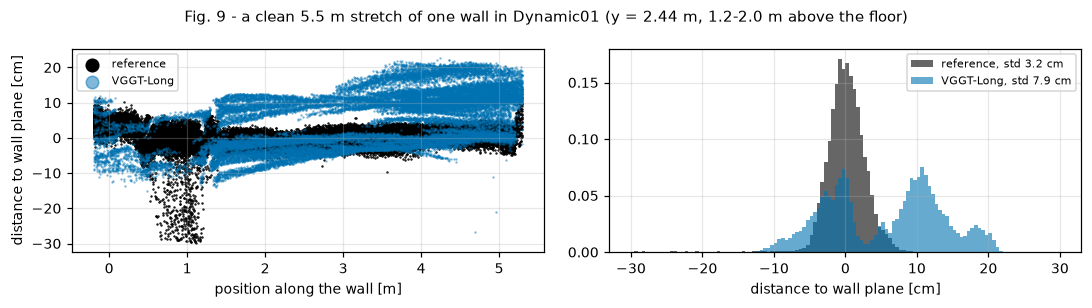

In [14]:
est, ref = maps["Dynamic01"]
z_floor = mm[mm.sequence == "Dynamic01"].floor_z_m.iloc[0]   # floor height found by pipeline.map_eval
band = lambda p: p[(p[:, 2] > z_floor + 1.2) & (p[:, 2] < z_floor + 2.0)]   # above furniture, below the ceiling
r_b, e_b = band(ref), band(est)

# strongest wall = densest x or y coordinate of the reference in that band
hx, ex = np.histogram(r_b[:, 0], bins=400); hy, ey = np.histogram(r_b[:, 1], bins=400)
axis = 0 if hx.max() > hy.max() else 1
edges, h = (ex, hx) if axis == 0 else (ey, hy)
w0 = edges[np.argmax(h)]
other = 1 - axis
near = lambda p: p[np.abs(p[:, axis] - w0) < 0.3]
wall_ref, wall_est = near(r_b), near(e_b)

# keep the longest stretch along the wall where the reference is thin (no shelves or boxes in front)
bins = np.arange(wall_ref[:, other].min(), wall_ref[:, other].max() + 0.5, 0.5)
which = np.digitize(wall_ref[:, other], bins)
thin = [np.subtract(*np.percentile(wall_ref[which == b, axis], [84, 16])) / 2 < 0.03
        if (which == b).sum() > 50 else False for b in range(1, len(bins))]
best, run, lo = (0, 0), 0, 0
for i, ok in enumerate(thin + [False]):
    if ok:
        run += 1
        if run > best[1] - best[0]:
            best = (i - run + 1, i + 1)
    else:
        run = 0
seg = (bins[best[0]], bins[best[1]])
inseg = lambda p: p[(p[:, other] > seg[0]) & (p[:, other] < seg[1])]
wall_ref, wall_est = inseg(wall_ref), inseg(wall_est)
c = wall_ref.mean(0); n = np.linalg.eigh(np.cov((wall_ref - c).T))[1][:, 0]   # plane normal = smallest direction
d_ref, d_est = (wall_ref - c) @ n, (wall_est - c) @ n

fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
axes[0].scatter(wall_ref[:, other], d_ref * 100, s=0.3, c="k", label="reference", rasterized=True)
axes[0].scatter(wall_est[:, other], d_est * 100, s=0.3, c=C_EST, alpha=0.5, label="VGGT-Long", rasterized=True)
axes[0].set_xlabel("position along the wall [m]"); axes[0].set_ylabel("distance to wall plane [cm]")
axes[0].legend(markerscale=15, fontsize=7)
hb = np.linspace(-30, 30, 121)
axes[1].hist(d_ref * 100, hb, color="k", alpha=0.6, density=True, label=f"reference, std {d_ref.std()*100:.1f} cm")
axes[1].hist(d_est * 100, hb, color=C_EST, alpha=0.6, density=True, label=f"VGGT-Long, std {d_est.std()*100:.1f} cm")
axes[1].set_xlabel("distance to wall plane [cm]"); axes[1].legend(fontsize=7)
fig.suptitle(f"Fig. 9 - a clean {seg[1] - seg[0]:.1f} m stretch of one wall in Dynamic01 "
             f"({'x' if axis == 0 else 'y'} = {w0:.2f} m, {1.2:.1f}-{2.0:.1f} m above the floor)", fontsize=10)
plt.tight_layout()

**Reading Section 6:** in the common volume, half of VGGT-Long's points lie within a few centimetres of the LiDAR
reference. Over the whole room completeness drops, because the camera never sees the ceiling: an honest
advantage of the LiDAR. MPV and Fig. 9 show the main difference in quality: VGGT-Long draws the same wall as
several parallel layers about 10 cm apart, one per lap, because the laps do not line up exactly; each layer on its own
is thin, the spread comes from the layers. The reference itself is not perfectly thin either (LiDAR noise of ~2 cm), which is why
its MPV is reported as the floor. People walking through `Dynamic01` are mapped by VGGT-Long but were filtered
from the reference, so they count as errors. `Varying-illu01` is left out of the map figures: its shrunken
reconstruction cannot be aligned (ICP rejected, see `icp_accepted` in `results/map_metrics.csv`).

## 6b. Does a LiDAR do better? FAST-LIO2 as backup

**FAST-LIO2** (Xu et al., T-RO 2022) is the opposite design: a LiDAR-inertial odometry with an iterated Kalman
filter, metric by construction, no learned parts and no loop closure. We run the version the M3DGR authors adapted
for their MID-360 (`baseline_systems/Fast_LIO2_M3DGR`, ROS 1, `docker/fast_lio2`), replaying the original bags in
real time on the CPU, 5 runs per sequence. The trajectory is metric, so the alignment is **SE(3)** (no scale).

In [15]:
fl = metrics[metrics.slug == "fast_lio2"]
if fl.empty:
    print("No FAST-LIO2 runs yet: python -m pipeline.run_all --system fast_lio2, then python -m pipeline.evaluate")
else:
    tab_fl = (fl.groupby("sequence").agg(success=("success", "sum"), runs=("run", "count"),
              ate_rmse_m=("ate_rmse_m", "median"), ate_iqr_m=("ate_rmse_m", iqr)).loc[SEQS])
    tab_fl["published_m"] = lit["FAST-LIO2 (LiDAR + IMU)"]
    tab_fl["vggt_long_m"] = tab.ate_rmse_m
    display(tab_fl.round(3))

,success,runs,ate_rmse_m,ate_iqr_m,published_m,vggt_long_m
sequence,,,,,,
Dynamic01,5,5,0.143,0.0,0.13,0.146
Sha-turn01,5,5,0.202,0.0,0.18,0.264
Varying-illu01,5,5,0.139,0.0,0.11,2.346


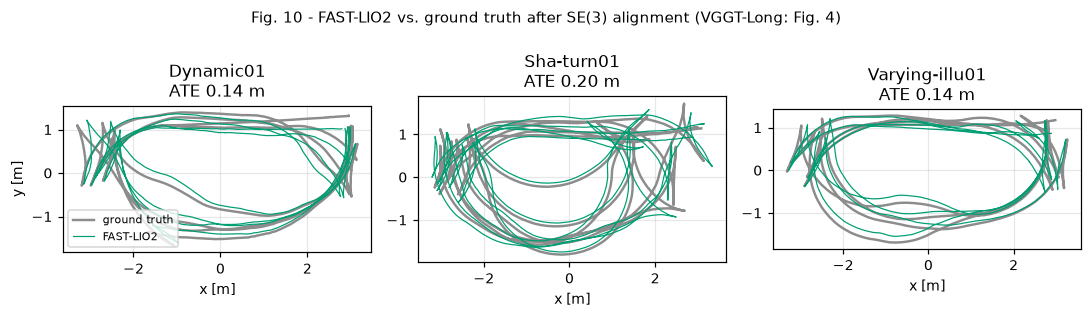

In [16]:
if not fl.empty:
    fig, axes = plt.subplots(1, 3, figsize=(10, 2.9))
    for ax, s in zip(axes, SEQS):
        ax.plot(GT[s].positions_xyz[:, 0], GT[s].positions_xyz[:, 1], c=C_GT, lw=1.6, label="ground truth")
        e_fl, _ = align_full(GT[s], load_est("fast_lio2", s), False, CFG["evaluation"]["t_max_diff"])
        ax.plot(e_fl.positions_xyz[:, 0], e_fl.positions_xyz[:, 1], c="#009E73", lw=0.8, label="FAST-LIO2")
        ax.set_aspect("equal"); ax.set_title(f"{s}\nATE {tab_fl.loc[s, 'ate_rmse_m']:.2f} m"); ax.set_xlabel("x [m]")
    axes[0].set_ylabel("y [m]"); axes[0].legend(fontsize=7, loc="lower left")
    fig.suptitle("Fig. 10 - FAST-LIO2 vs. ground truth after SE(3) alignment (VGGT-Long: Fig. 4)", fontsize=10)
    plt.tight_layout()

**Where do FAST-LIO2's 14-20 cm come from?** A LiDAR-inertial system on a slow robot in a small hall should be
better than that. The suspect is the **lever arm**: FAST-LIO2 estimates the pose of the MID-360's IMU, the ground
truth is the pose of the motion-capture marker body, and M3DGR does not give the transform between the two. A
constant offset between two points on a rigid robot cannot be removed by any trajectory alignment: every time the
robot turns, the two points move differently. As a diagnostic we estimate the offset `l` (in the IMU frame) jointly
with the alignment, by least squares, separately for each sequence.

In [17]:
def umeyama(a, b):
    ma, mb = a.mean(0), b.mean(0)
    U, _, Vt = np.linalg.svd((b - mb).T @ (a - ma))
    D = np.diag([1, 1, np.sign(np.linalg.det(U @ Vt))])
    R = U @ D @ Vt
    return R, mb - R @ ma


def fit_lever_arm(slug, seq, iters=30):
    # gt ~ R (p + R_est l) + t: alternate SE(3) alignment and linear least squares for l
    r, e = sync.associate_trajectories(GT[seq], load_est(slug, seq), max_diff=CFG["evaluation"]["t_max_diff"])
    G, P, Re = r.positions_xyz, e.positions_xyz, np.array(e.poses_se3)[:, :3, :3]
    l = np.zeros(3)
    for _ in range(iters):
        R, t = umeyama(P + Re @ l, G)
        A = np.einsum("ij,njk->nik", R, Re).reshape(-1, 3)
        l = np.linalg.lstsq(A, (G - P @ R.T - t).ravel(), rcond=None)[0]
    R, t = umeyama(P + Re @ l, G)
    return l, np.sqrt((((P + Re @ l) @ R.T + t - G) ** 2).sum(1).mean())


if not fl.empty:
    rows = {}
    for s in SEQS:
        l, ate_l = fit_lever_arm("fast_lio2", s)
        rows[s] = {"ate_m": tab_fl.loc[s, "ate_rmse_m"], "ate_with_lever_arm_m": ate_l,
                   "l_x_m": l[0], "l_y_m": l[1], "l_z_m": l[2]}
    lever = pd.DataFrame(rows).T
    display(lever.round(3))

,ate_m,ate_with_lever_arm_m,l_x_m,l_y_m,l_z_m
Dynamic01,0.143,0.011,-0.141,-0.127,-0.076
Sha-turn01,0.202,0.012,-0.142,-0.128,-0.076
Varying-illu01,0.139,0.007,-0.140,-0.125,-0.077


**Reading Table / Fig. 10:** FAST-LIO2 never fails, not even in the dark (a LiDAR does not need light), and with its
fitted offset its error drops from 14-20 cm to about **1 cm** on every sequence. The offset itself comes out the
same on all three recordings to within about 2 mm, about 19 cm horizontally. Three
independent recordings agreeing on one rigid offset is what a physical lever arm looks like, not overfitting.
Two consequences:

1. Most of FAST-LIO2's ATE, and most of the published 0.11-0.18 m, is **the mocap-to-sensor offset, not drift**. Our
   values sit 1-3 cm above the published ones; details of the protocol (timestamp association, alignment)
   are enough to explain that, so they are consistent.
2. The same offset exists for every system, also for VGGT-Long's camera. For VGGT-Long, however, a fitted offset is
   not identifiable: it comes out different on every sequence because it absorbs real drift as well. The main
   tables therefore keep the standard protocol (no offset), as in M3DGR, and this is noted as a limitation.

The map comparison below has a built-in bias: the reference map is made from the **same MID-360 scans**,
placed with mocap poses. FAST-LIO2's map differs from it only through its pose errors, so its scores are an upper
bound and not a fair contest with a camera.

In [18]:
mm_all = pd.read_csv(RES / "map_metrics.csv")
cmp_map = mm_all[(mm_all.slug.isin(["vggt_long", "fast_lio2"])) & (mm_all.stage == "icp_refined")
                 & (mm_all.region == "common")]
cols_map = ["accuracy_median_m", "completeness_median_m", "fscore_5cm", "fscore_10cm", "iou_10cm", "mpv_est_m2"]
cmp_map = cmp_map.set_index(["sequence", "slug"])[cols_map + ["icp_accepted"]].sort_index()
cmp_map["mpv_est_cm2"] = cmp_map.pop("mpv_est_m2") * 1e4
cmp_map

accuracy_median_m  completeness_median_m  \
sequence       slug                                                  
Dynamic01      fast_lio2              0.012                  0.012   
               vggt_long              0.030                  0.033   
Sha-turn01     fast_lio2              0.011                  0.013   
               vggt_long              0.047                  0.026   
Varying-illu01 fast_lio2              0.010                  0.012   
               vggt_long              0.450                  3.233   

                          fscore_5cm  fscore_10cm  iou_10cm  icp_accepted  \
sequence       slug                                                         
Dynamic01      fast_lio2       0.883        0.892     0.401          True   
               vggt_long       0.609        0.740     0.263          True   
Sha-turn01     fast_lio2       0.983        0.990     0.643          True   
               vggt_long       0.571        0.713     0.200          True   
Varying-illu01 fast_lio2       0.983        0.990     0.674          True   
               vggt_long       0.008        0.016     0.004         False   

                          mpv_est_cm2  
sequence       slug                    
Dynamic01      fast_lio2        5.718  
               vggt_long       10.150  
Sha-turn01     fast_lio2        3.927  
               vggt_long       10.701  
Varying-illu01 fast_lio2        3.592  
               vggt_long       10.344

**Reading the map table:** FAST-LIO2's map lies within about 1 cm of the reference and reaches F-scores of
0.9-1.0, VGGT-Long's within about 3-5 cm at 0.71-0.74. Given the shared scans this gap is expected and not the
point; the point is that the reference is consistent with an independent LiDAR-inertial map. On `Dynamic01`
FAST-LIO2 scores lower than on the other two, because it maps the people walking through the hall, which the
reference filters out. FAST-LIO2's MPV (3.6-5.7 cm²) is around that of the reference (~4.9 cm²) and about half of VGGT-Long's.

## 7. What does a 16 GB laptop GPU cost in accuracy?

Same system, same images, chunk 30 instead of 60. Resources are measurements on different hardware, reported
for context, not for ranking. GPU memory comes from `nvidia-smi` and is valid on both; CPU and RAM are
left out, because for local Docker runs on Windows the sampler only sees the `wsl.exe` process, not the container.

In [19]:
lap = metrics[metrics.slug == "vggt_long_16gb"]
if lap.empty:
    print("No laptop runs yet: python -m pipeline.run_all --system vggt_long_16gb, then python -m pipeline.evaluate")
else:
    both = metrics[metrics.slug.isin(["vggt_long", "vggt_long_16gb"])]
    cmp = (both.groupby(["sequence", "slug"])
           .agg(runs=("run", "count"), ate_rmse_m=("ate_rmse_m", "median"), scale=("scale", "median"),
                wall_time_min=("wall_time_s", lambda x: x.median() / 60),
                gpu_peak_gb=("gpu_mem_peak_mib", lambda x: x.median() / 1024))
           .unstack("slug"))
    mm_lap = pd.read_csv(RES / "map_metrics.csv")
    mm_lap = mm_lap[mm_lap.slug.isin(["vggt_long", "vggt_long_16gb"]) & (mm_lap.stage == "icp_refined")
                    & (mm_lap.region == "common")]
    f10 = mm_lap.pivot(index="sequence", columns="slug", values="fscore_10cm")
    f10.columns = pd.MultiIndex.from_product([["map_fscore_10cm"], f10.columns])
    cmp = cmp.join(f10)
    display(cmp.round(3))

runs                ate_rmse_m                    scale  \
slug           vggt_long vggt_long_16gb  vggt_long vggt_long_16gb vggt_long   
sequence                                                                      
Dynamic01              5              1      0.146          0.142     5.241   
Sha-turn01             5              1      0.264          0.417     5.811   
Varying-illu01         5              1      2.346          2.229     2.076   

                              wall_time_min                gpu_peak_gb  \
slug           vggt_long_16gb     vggt_long vggt_long_16gb   vggt_long   
sequence                                                                 
Dynamic01               5.003        16.251         33.290      35.111   
Sha-turn01              4.756        14.219         30.098      40.674   
Varying-illu01          2.496        14.811         30.372      40.420   

                              map_fscore_10cm                 
slug           vggt_long_16gb       vggt_long vggt_long_16gb  
sequence                                                      
Dynamic01               15.25           0.740          0.694  
Sha-turn01              15.25           0.713          0.607  
Varying-illu01          15.25           0.016          0.134

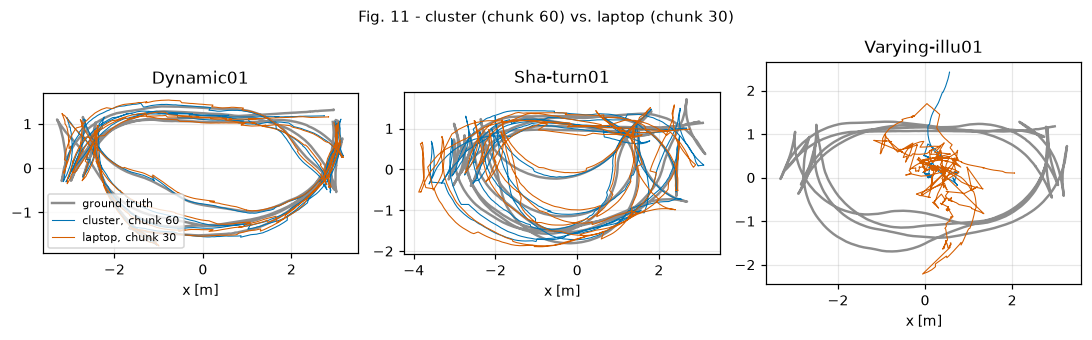

In [20]:
if not lap.empty:
    seqs = [s for s in SEQS if s in set(lap.sequence)]
    fig, axes = plt.subplots(1, len(seqs), figsize=(10, 2.9), squeeze=False)
    for ax, s in zip(axes[0], seqs):
        ax.plot(GT[s].positions_xyz[:, 0], GT[s].positions_xyz[:, 1], c=C_GT, lw=1.6, label="ground truth")
        for slug, col, lab in (("vggt_long", C_EST, "cluster, chunk 60"), ("vggt_long_16gb", C_LAP, "laptop, chunk 30")):
            e, _ = aligned(slug, s)
            ax.plot(e.positions_xyz[:, 0], e.positions_xyz[:, 1], c=col, lw=0.7, label=lab)
        ax.set_aspect("equal"); ax.set_title(s); ax.set_xlabel("x [m]")
    axes[0][0].legend(fontsize=7, loc="lower left")
    fig.suptitle("Fig. 11 - cluster (chunk 60) vs. laptop (chunk 30)", fontsize=10)
    plt.tight_layout()

**Reading Section 7:** halving the chunk costs nothing in ATE on `Dynamic01` (slow, smooth driving; the map F-score
drops slightly, 0.69 vs. 0.74) but clearly hurts on `Sha-turn01` (ATE 0.42 vs. 0.26 m, F-score 0.61 vs. 0.71): with 30 frames per chunk at 10 Hz each VGGT pass sees only 3 s of a fast, sharply turning drive, so
the overlap between neighbouring chunks carries less shared geometry and the Sim(3) links between chunks get
worse. `Varying-illu01` fails on both machines for the reason shown in Section 5. On the laptop the run takes
about twice as long and fits into 16 GB. GPU memory is what `nvidia-smi` sees, i.e. what PyTorch's
caching allocator reserves: on the large cluster GPU it keeps more and the peak varies between identical
runs (28-45 GB), so that column is an upper bound, not the memory the model needs. The main results therefore stay on the cluster with the authors' defaults;
the laptop shows that the method runs on a consumer GPU, at a price on the hardest motion.

## 8. Live demo in Lichtblick / Foxglove

`pipeline/visualize.py` writes a 3D replay of a run as MCAP: ground truth and estimate as paths and poses, the
error line between them, the camera image, image brightness and both maps. It plays in **Lichtblick** (the open
source fork of Foxglove Studio), which runs locally as a container. One command builds the replay if needed,
starts Lichtblick with the prepared layout on `http://localhost:8081` plus a small file server on port 8791,
and opens the browser at the right file:

```bash
python tools/demo.py                                   # VGGT-Long, Dynamic01
python tools/demo.py --sequence Sha-turn01             # any other sequence
python tools/demo.py --system fast_lio2 --sequence Varying-illu01
```

The replay is for plausibility checks and the presentation; all numbers come from `pipeline.evaluate` and
`pipeline.map_eval`.

In [21]:
mcaps = sorted(RES.glob("*/*/run_00/viz/*.mcap"))
print("\n".join(str(m.relative_to(ROOT)) for m in mcaps) or "no replay built yet (python tools/demo.py builds one)")

no replay built yet (python tools/demo.py builds one)


## 9. Take-aways

1. **Where there is light, it works well.** 0.15-0.26 m ATE (0.2-0.3 % of the distance) and a room map within a
   few centimetres, from one uncalibrated camera and without any training on this data.
2. **Darkness causes a silent failure.** Every frame still gets a pose, but black chunks break the scale between
   chunks and the whole reconstruction shrinks. Tracked fraction misses it; ATE, scale factor and map metrics
   catch it.
3. **Walls come out thicker than with a LiDAR.** Accuracy and MPV quantify the noise of the camera-based
   geometry; completeness is limited to what the camera can see.
4. **Fully deterministic.** Repeated runs agree to below a millimetre; repetitions do not add information.
5. **Hardware.** The default configuration needs a large GPU (28-45 GB reserved on the cluster). On a 16 GB laptop GPU with half-size
   chunks it is as good on smooth driving but clearly worse on sharp turns (Section 7).
6. **The ground truth has a lever arm.** FAST-LIO2's 14-20 cm ATE is almost entirely the unknown offset between
   the mocap body and the sensor (about 1 cm once it is fitted, Section 6b). Absolute ATE values on M3DGR,
   including the published ones, therefore contain a constant offset term of this size.